In [ ]:
# Unzip your dataset in /content/HW3
!unzip -q "/content/Data.zip" -d "/content/HW3"


In [ ]:
import os
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from datetime import datetime

# Paths
train_img_dir = '/content/HW3/Data/train/image'
train_mask_dir = '/content/HW3/Data/train/mask'
test_img_dir = '/content/HW3/Data/test/image'
test_mask_dir = '/content/HW3/Data/test/mask'

# 1) How many data samples?
train_imgs = os.listdir(train_img_dir)
test_imgs = os.listdir(test_img_dir)
train_masks = os.listdir(train_mask_dir)
test_masks = os.listdir(test_mask_dir)
print("="*60)
print("STEP 1: DATA INSPECTION")
print("="*60)
print(f"1) Data samples: Train={len(train_imgs)}, Test={len(test_imgs)}, Total={len(train_imgs)+len(test_imgs)}")

# 2) Problem addressed
print(f"2) Problem: Retinal blood vessel segmentation from fundus images")

# 3) Dimension range
all_img_paths = [os.path.join(train_img_dir, img) for img in train_imgs] + \
                [os.path.join(test_img_dir, img) for img in test_imgs]
sizes = [Image.open(path).size for path in all_img_paths]
widths, heights = zip(*sizes)
print(f"3) Dimension range: Width [{min(widths)}, {max(widths)}], Height [{min(heights)}, {max(heights)}]")

# 4) Missing information
missing_train = set(train_imgs) ^ set(train_masks)
missing_test = set(test_imgs) ^ set(test_masks)
print(f"4) Missing data: Train={len(missing_train)}, Test={len(missing_test)} (0 means no missing files)")

# 5) Labels
sample_mask = np.array(Image.open(os.path.join(train_mask_dir, train_masks[0])).convert('L'))
unique_vals = np.unique(sample_mask)
print(f"5) Label format: Binary mask (vessel=white, background=black). Raw values: {unique_vals}")

# 6) Train/Val/Test split
n_train = len(train_imgs)
n_test = len(test_imgs)
total = n_train + n_test
train_pct = round(100 * n_train / total, 2)
test_pct = round(100 * n_test / total, 2)
print(f"6) Data split: Training={train_pct}%, Testing={test_pct}% (no separate validation set used)")

# 7) Preprocessing
print(f"7) Preprocessing: Images normalized to [0,1]; Masks binarized (threshold=127) to [0,1]; BatchNorm in U-Net")
print("="*60)


STEP 1: DATA INSPECTION
1) Data samples: Train=80, Test=20, Total=100
2) Problem: Retinal blood vessel segmentation from fundus images
3) Dimension range: Width [512, 512], Height [512, 512]
4) Missing data: Train=0, Test=0 (0 means no missing files)
5) Label format: Binary mask (vessel=white, background=black). Raw values: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 

In [ ]:
class RetinalDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_files = sorted([
            os.path.join(img_dir, f) for f in os.listdir(img_dir)
            if f.lower().endswith(('png','jpg','bmp','tif','jpeg'))
        ])
        self.mask_files = sorted([
            os.path.join(mask_dir, f) for f in os.listdir(mask_dir)
            if f.lower().endswith(('png','jpg','bmp','tif','jpeg'))
        ])
    def __len__(self):
        return len(self.img_files)
    def __getitem__(self, idx):
        img = np.array(Image.open(self.img_files[idx]).convert('RGB')) / 255.0
        mask_raw = np.array(Image.open(self.mask_files[idx]).convert('L'))  # Keep raw 0-255
        mask_normalized = (mask_raw > 127).astype(np.float32)  # Binarize to 0/1

        img = np.transpose(img, (2,0,1)).astype(np.float32)  # CHW
        mask_normalized = mask_normalized[np.newaxis, ...]  # Add channel dim
        mask_raw = mask_raw[np.newaxis, ...].astype(np.float32)  # Add channel dim, keep raw values

        return torch.tensor(img), torch.tensor(mask_normalized), torch.tensor(mask_raw)


In [ ]:
def dice_loss(pred, target, eps=1e-7):
    pred = pred.contiguous().view(-1)
    target = target.contiguous().view(-1)
    intersection = (pred * target).sum()
    return 1 - (2. * intersection + eps) / (pred.sum() + target.sum() + eps)

class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCELoss()
    def forward(self, pred, target):
        return self.bce(pred, target) + dice_loss(pred, target)

def dice_score(pred, target, eps=1e-7):
    pred_bin = (pred > 0.5).float()
    target_bin = (target > 0.5).float()
    intersection = (pred_bin * target_bin).sum()
    return (2 * intersection) / (pred_bin.sum() + target_bin.sum() + eps)

def iou_score(pred, target, eps=1e-7):
    pred_bin = (pred > 0.5).float()
    target_bin = (target > 0.5).float()
    intersection = (pred_bin * target_bin).sum()
    union = pred_bin.sum() + target_bin.sum() - intersection
    return intersection / (union + eps)


In [ ]:
def dice_score_unnormalized(pred, target_raw_255, eps=1e-7):
    """
    Calculate Dice on raw mask (0-255 grayscale) vs prediction (0-1 thresholded).
    Normalizes raw mask by 255 before computing Dice.
    """
    pred_bin = (pred > 0.5).float()
    target_norm = (target_raw_255 / 255.0).float()  # Normalize 0-255 to 0-1
    target_bin = (target_norm > 0.5).float()  # Threshold at 0.5
    intersection = (pred_bin * target_bin).sum()
    return (2 * intersection) / (pred_bin.sum() + target_bin.sum() + eps)

def iou_score_unnormalized(pred, target_raw_255, eps=1e-7):
    """
    Calculate IoU on raw mask (0-255 grayscale) vs prediction (0-1 thresholded).
    """
    pred_bin = (pred > 0.5).float()
    target_norm = (target_raw_255 / 255.0).float()
    target_bin = (target_norm > 0.5).float()
    intersection = (pred_bin * target_bin).sum()
    union = pred_bin.sum() + target_bin.sum() - intersection
    return intersection / (union + eps)


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class UNet2(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base_filters=32):
        super().__init__()
        self.enc1 = ConvBlock(in_ch, base_filters)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(base_filters, base_filters*2)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(base_filters*2, base_filters*4)
        self.up2 = nn.ConvTranspose2d(base_filters*4, base_filters*2, 2, stride=2)
        self.dec2 = ConvBlock(base_filters*4, base_filters*2)
        self.up1 = nn.ConvTranspose2d(base_filters*2, base_filters, 2, stride=2)
        self.dec1 = ConvBlock(base_filters*2, base_filters)
        self.final = nn.Conv2d(base_filters, out_ch, 1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.pool1(enc1))
        bottleneck = self.bottleneck(self.pool2(enc2))
        up2 = self.up2(bottleneck)
        cat2 = torch.cat([up2, enc2], dim=1)
        dec2 = self.dec2(cat2)
        up1 = self.up1(dec2)
        cat1 = torch.cat([up1, enc1], dim=1)
        dec1 = self.dec1(cat1)
        return torch.sigmoid(self.final(dec1))

class UNet3(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base_filters=32):
        super().__init__()
        self.enc1 = ConvBlock(in_ch, base_filters)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(base_filters, base_filters*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(base_filters*2, base_filters*4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(base_filters*4, base_filters*8)
        self.up3 = nn.ConvTranspose2d(base_filters*8, base_filters*4, 2, stride=2)
        self.dec3 = ConvBlock(base_filters*8, base_filters*4)
        self.up2 = nn.ConvTranspose2d(base_filters*4, base_filters*2, 2, stride=2)
        self.dec2 = ConvBlock(base_filters*4, base_filters*2)
        self.up1 = nn.ConvTranspose2d(base_filters*2, base_filters, 2, stride=2)
        self.dec1 = ConvBlock(base_filters*2, base_filters)
        self.final = nn.Conv2d(base_filters, out_ch, 1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.pool1(enc1))
        enc3 = self.enc3(self.pool2(enc2))
        bottleneck = self.bottleneck(self.pool3(enc3))
        up3 = self.up3(bottleneck)
        cat3 = torch.cat([up3, enc3], dim=1)
        dec3 = self.dec3(cat3)
        up2 = self.up2(dec3)
        cat2 = torch.cat([up2, enc2], dim=1)
        dec2 = self.dec2(cat2)
        up1 = self.up1(dec2)
        cat1 = torch.cat([up1, enc1], dim=1)
        dec1 = self.dec1(cat1)
        return torch.sigmoid(self.final(dec1))
class UNet4(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base_filters=32):
        super().__init__()
        self.enc1 = ConvBlock(in_ch, base_filters)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(base_filters, base_filters*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(base_filters*2, base_filters*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(base_filters*4, base_filters*8)
        self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(base_filters*8, base_filters*16)
        self.up4 = nn.ConvTranspose2d(base_filters*16, base_filters*8, 2, stride=2)
        self.dec4 = ConvBlock(base_filters*16, base_filters*8)
        self.up3 = nn.ConvTranspose2d(base_filters*8, base_filters*4, 2, stride=2)
        self.dec3 = ConvBlock(base_filters*8, base_filters*4)
        self.up2 = nn.ConvTranspose2d(base_filters*4, base_filters*2, 2, stride=2)
        self.dec2 = ConvBlock(base_filters*4, base_filters*2)
        self.up1 = nn.ConvTranspose2d(base_filters*2, base_filters, 2, stride=2)
        self.dec1 = ConvBlock(base_filters*2, base_filters)
        self.final = nn.Conv2d(base_filters, out_ch, 1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.pool1(enc1))
        enc3 = self.enc3(self.pool2(enc2))
        enc4 = self.enc4(self.pool3(enc3))
        bottleneck = self.bottleneck(self.pool4(enc4))
        up4 = self.up4(bottleneck)
        cat4 = torch.cat([up4, enc4], dim=1)
        dec4 = self.dec4(cat4)
        up3 = self.up3(dec4)
        cat3 = torch.cat([up3, enc3], dim=1)
        dec3 = self.dec3(cat3)
        up2 = self.up2(dec3)
        cat2 = torch.cat([up2, enc2], dim=1)
        dec2 = self.dec2(cat2)
        up1 = self.up1(dec2)
        cat1 = torch.cat([up1, enc1], dim=1)
        dec1 = self.dec1(cat1)
        return torch.sigmoid(self.final(dec1))


In [ ]:
EPOCHS = 15
BATCH_SIZE = 4
LR = 1e-3
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
NetDict = {2: UNet2, 3: UNet3, 4: UNet4}

# Dictionary to store results
results = {}

for blocks in [2, 3, 4]:
    start_time = datetime.now()
    print(f"\n{'='*80}")
    print(f"Training U-Net with {blocks} blocks...")
    print(f"Start Time: {start_time.strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"{'='*80}")

    NetClass = NetDict[blocks]
    model = NetClass(in_ch=3, out_ch=1, base_filters=32).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = DiceBCELoss()
    train_ds = RetinalDataset(train_img_dir, train_mask_dir)
    test_ds = RetinalDataset(test_img_dir, test_mask_dir)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=1)

    for epoch in range(EPOCHS):
        model.train()
        train_loss, train_dice, train_iou = [], [], []
        for batch_idx, (imgs, masks_norm, masks_raw) in enumerate(train_loader):
            imgs, masks_norm = imgs.to(DEVICE), masks_norm.to(DEVICE)
            preds = model(imgs)
            loss = loss_fn(preds, masks_norm)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())
            train_dice.append(dice_score(preds, masks_norm).item() if torch.is_tensor(dice_score(preds, masks_norm)) else dice_score(preds, masks_norm))
            train_iou.append(iou_score(preds, masks_norm).item() if torch.is_tensor(iou_score(preds, masks_norm)) else iou_score(preds, masks_norm))

        train_loss_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in train_loss]
        train_dice_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in train_dice]
        train_iou_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in train_iou]
        print(f"Epoch {epoch+1}/{EPOCHS}: Loss={np.mean(train_loss_cpu):.4f}, Dice={np.mean(train_dice_cpu):.4f}, IoU={np.mean(train_iou_cpu):.4f}")

    # Test evaluation
    model.eval()
    dices_norm, ious_norm = [], []
    dices_unnorm, ious_unnorm = [], []

    with torch.no_grad():
        for imgs, masks_norm, masks_raw in test_loader:
            imgs, masks_norm, masks_raw = imgs.to(DEVICE), masks_norm.to(DEVICE), masks_raw.to(DEVICE)
            preds = model(imgs)

            # Normalized metrics
            dices_norm.append(dice_score(preds, masks_norm))
            ious_norm.append(iou_score(preds, masks_norm))

            # Unnormalized metrics
            dices_unnorm.append(dice_score_unnormalized(preds, masks_raw))
            ious_unnorm.append(iou_score_unnormalized(preds, masks_raw))

    # Convert to CPU floats
    dices_norm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in dices_norm]
    ious_norm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in ious_norm]
    dices_unnorm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in dices_unnorm]
    ious_unnorm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in ious_unnorm]

    end_time = datetime.now()
    duration = end_time - start_time

    # Store results
    results[blocks] = {
        'dice_norm': np.mean(dices_norm_cpu),
        'iou_norm': np.mean(ious_norm_cpu),
        'dice_unnorm': np.mean(dices_unnorm_cpu),
        'iou_unnorm': np.mean(ious_unnorm_cpu),
    }

    print(f"\n{'='*80}")
    print(f"U-Net {blocks} blocks - FINAL TEST RESULTS")
    print(f"{'='*80}")
    print(f"NORMALIZED (binary masks):")
    print(f"  Test Dice: {np.mean(dices_norm_cpu):.4f}, Test IoU: {np.mean(ious_norm_cpu):.4f}")
    print(f"UNNORMALIZED (from raw 0-255 masks):")
    print(f"  Test Dice: {np.mean(dices_unnorm_cpu):.4f}, Test IoU: {np.mean(ious_unnorm_cpu):.4f}")
    print(f"End Time: {end_time.strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"Training Duration: {duration}")
    print(f"{'='*80}\n")

    torch.save(model.state_dict(), f'/content/HW3/best_unet_{blocks}blocks.pth')

# Print final summary table
print("\n" + "="*100)
print("FINAL RESULTS TABLE - STEP 5: MODEL SELECTION")
print("="*100)
print(f"{'Model':<20} {'Dice (Norm)':<15} {'IoU (Norm)':<15} {'Dice (Unnorm)':<15} {'IoU (Unnorm)':<15}")
print("-"*100)
for blocks in [2, 3, 4]:
    print(f"U-Net {blocks} blocks  {results[blocks]['dice_norm']:<15.4f} {results[blocks]['iou_norm']:<15.4f} {results[blocks]['dice_unnorm']:<15.4f} {results[blocks]['iou_unnorm']:<15.4f}")
print("="*100)



Training U-Net with 2 blocks...
Start Time: 2025-11-14 03:09:53
Epoch 1/15: Loss=1.4380, Dice=0.3856, IoU=0.2478
Epoch 2/15: Loss=1.2196, Dice=0.6439, IoU=0.4758
Epoch 3/15: Loss=1.1346, Dice=0.6939, IoU=0.5320
Epoch 4/15: Loss=1.0508, Dice=0.7145, IoU=0.5565
Epoch 5/15: Loss=0.9699, Dice=0.7340, IoU=0.5802
Epoch 6/15: Loss=0.8915, Dice=0.7450, IoU=0.5943
Epoch 7/15: Loss=0.8172, Dice=0.7567, IoU=0.6089
Epoch 8/15: Loss=0.7467, Dice=0.7683, IoU=0.6240
Epoch 9/15: Loss=0.6969, Dice=0.7622, IoU=0.6162
Epoch 10/15: Loss=0.6381, Dice=0.7733, IoU=0.6308
Epoch 11/15: Loss=0.5850, Dice=0.7807, IoU=0.6405
Epoch 12/15: Loss=0.5472, Dice=0.7809, IoU=0.6413
Epoch 13/15: Loss=0.5100, Dice=0.7855, IoU=0.6470
Epoch 14/15: Loss=0.4777, Dice=0.7900, IoU=0.6531
Epoch 15/15: Loss=0.4510, Dice=0.7927, IoU=0.6568

U-Net 2 blocks - FINAL TEST RESULTS
NORMALIZED (binary masks):
  Test Dice: 0.7884, Test IoU: 0.6510
UNNORMALIZED (from raw 0-255 masks):
  Test Dice: 0.7884, Test IoU: 0.6510
End Time: 2025-11

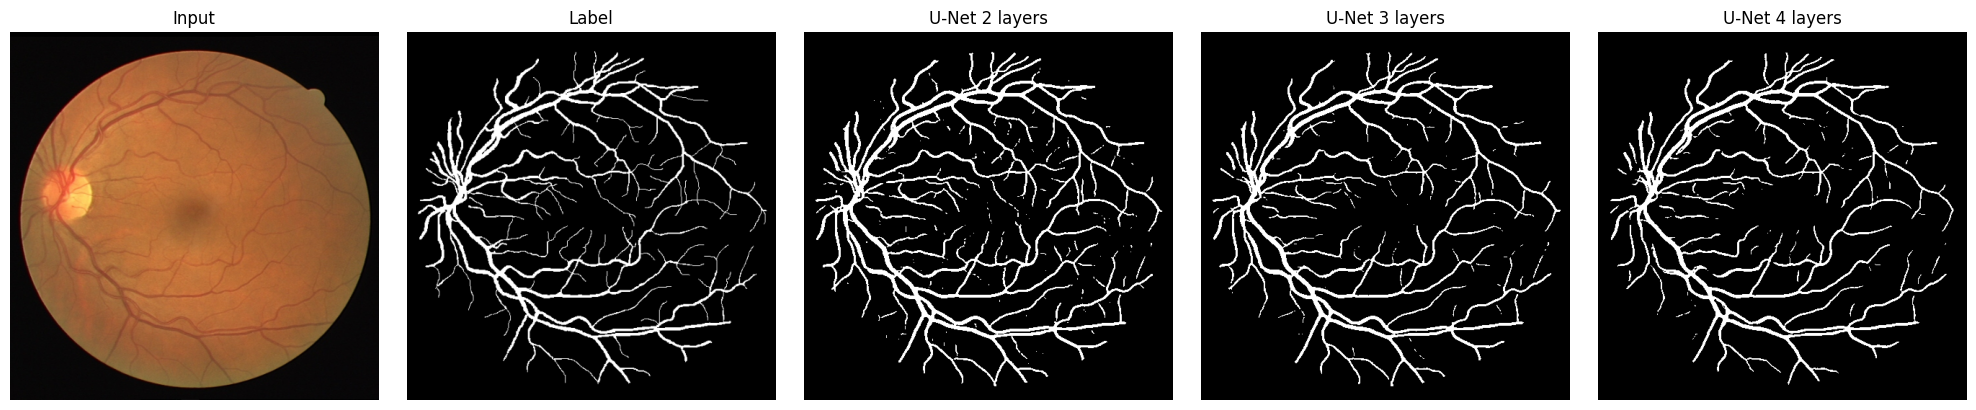

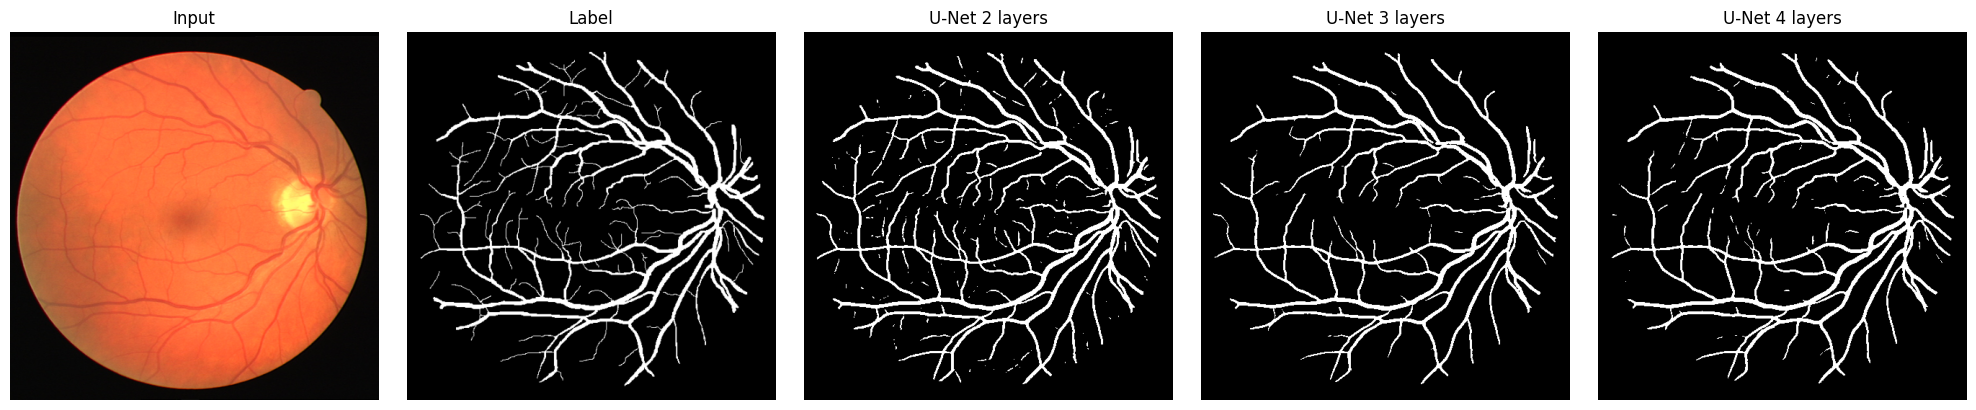

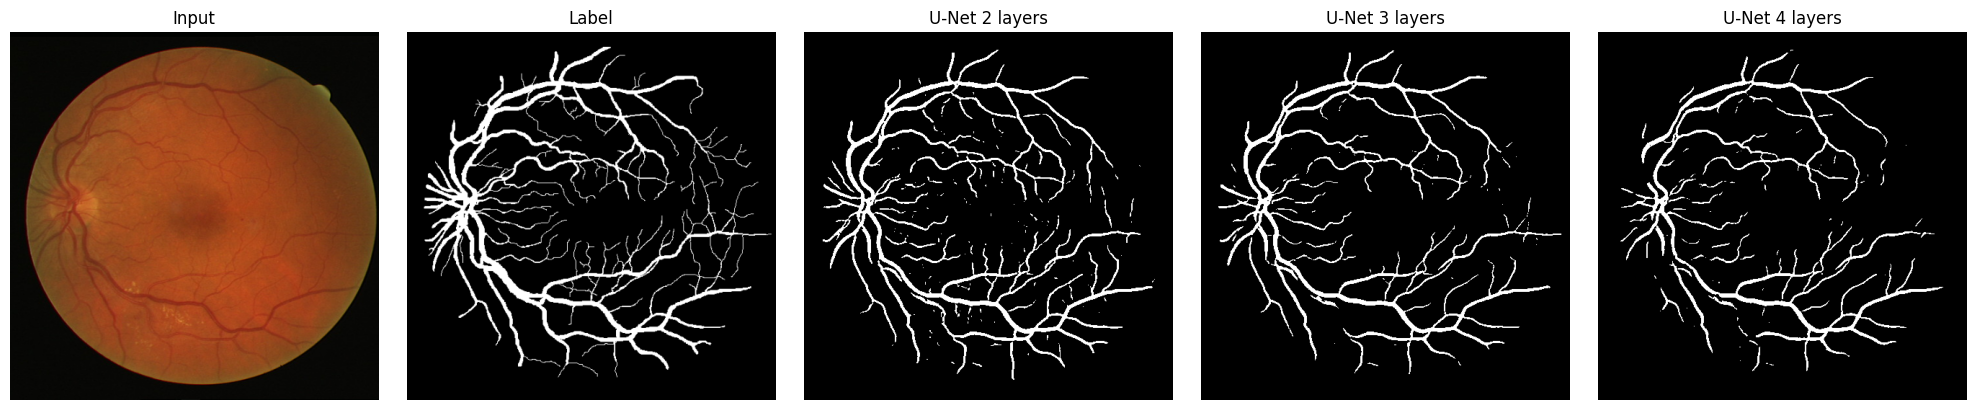

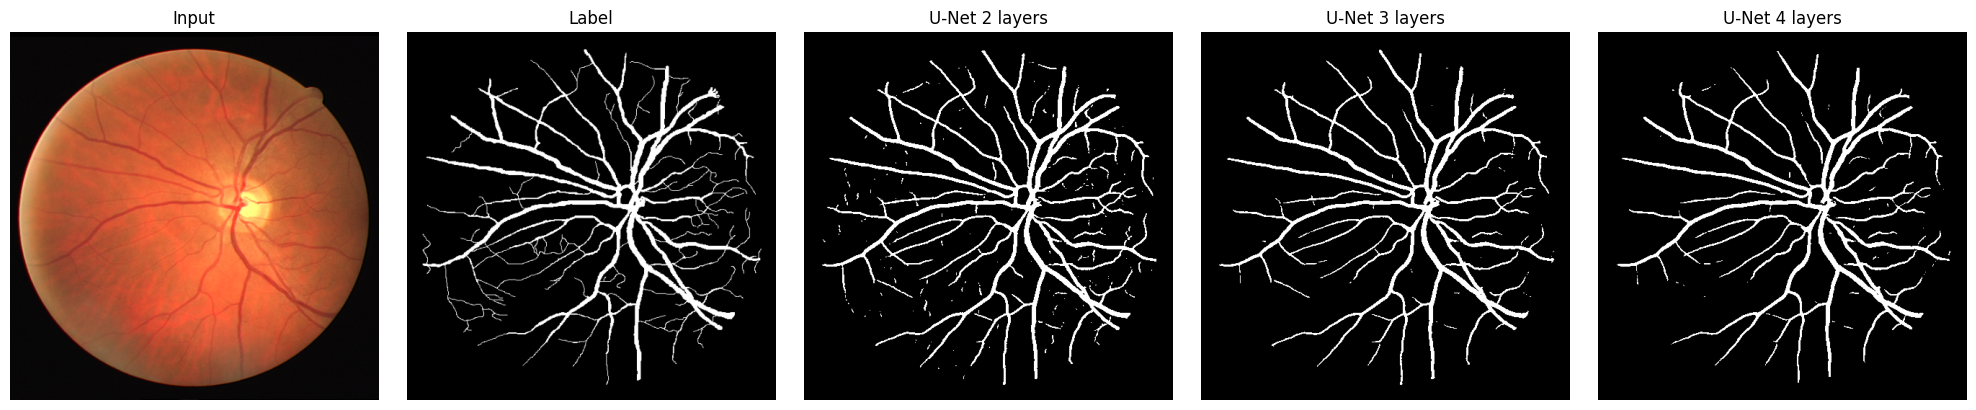

In [ ]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
for idx in range(4):
    img_path = f'{test_img_dir}/{idx}.png'
    mask_path = f'{test_mask_dir}/{idx}.png'
    img = Image.open(img_path)
    label = Image.open(mask_path)
    img_np = np.array(img) / 255.0
    img_tensor = torch.tensor(np.transpose(img_np, (2, 0, 1)), dtype=torch.float32).unsqueeze(0).to(DEVICE)

    model2 = UNet2(in_ch=3, out_ch=1, base_filters=32).to(DEVICE)
    model2.load_state_dict(torch.load('/content/HW3/best_unet_2blocks.pth', map_location=DEVICE))
    model2.eval()

    model3 = UNet3(in_ch=3, out_ch=1, base_filters=32).to(DEVICE)
    model3.load_state_dict(torch.load('/content/HW3/best_unet_3blocks.pth', map_location=DEVICE))
    model3.eval()

    model4 = UNet4(in_ch=3, out_ch=1, base_filters=32).to(DEVICE)
    model4.load_state_dict(torch.load('/content/HW3/best_unet_4blocks.pth', map_location=DEVICE))
    model4.eval()

    with torch.no_grad():
        pred_2 = model2(img_tensor).cpu().squeeze().numpy() > 0.5
        pred_3 = model3(img_tensor).cpu().squeeze().numpy() > 0.5
        pred_4 = model4(img_tensor).cpu().squeeze().numpy() > 0.5

    plt.figure(figsize=(20, 4))
    plt.subplot(1, 5, 1); plt.title('Input'); plt.imshow(img); plt.axis('off')
    plt.subplot(1, 5, 2); plt.title('Label'); plt.imshow(label, cmap='gray'); plt.axis('off')
    plt.subplot(1, 5, 3); plt.title('U-Net 2 layers'); plt.imshow(pred_2, cmap='gray'); plt.axis('off')
    plt.subplot(1, 5, 4); plt.title('U-Net 3 layers'); plt.imshow(pred_3, cmap='gray'); plt.axis('off')
    plt.subplot(1, 5, 5); plt.title('U-Net 4 layers'); plt.imshow(pred_4, cmap='gray'); plt.axis('off')
    plt.tight_layout()
    plt.savefig(f'/content/HW3/model_demo_{idx}.png')
    plt.show()


In [ ]:
def test_model(model_path, test_img_dir, test_mask_dir, model_type=2, device=None):
    """
    Load trained model weights and evaluate on test dataset.

    Args:
        model_path (str): Path to saved model weights (.pth file)
        test_img_dir (str): Directory containing test images
        test_mask_dir (str): Directory containing test masks
        model_type (int): Type of U-Net (2, 3, or 4 blocks)
        device (str): Device to run on ('cuda' or 'cpu')

    Returns:
        dict: Dictionary with dice_norm, iou_norm, dice_unnorm, iou_unnorm
    """
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'


    print(f"Testing U-Net model (type: {model_type} blocks)")
    print(f"Model path: {model_path}")
    print(f"Device: {device}")


    # Select model class
    model_dict = {2: UNet2, 3: UNet3, 4: UNet4}
    if model_type not in model_dict:
        raise ValueError(f"Invalid model_type. Choose from {list(model_dict.keys())}")

    ModelClass = model_dict[model_type]

    # Load model and weights
    model = ModelClass(in_ch=3, out_ch=1, base_filters=32).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Model loaded successfully from {model_path}")

    # Create test dataset and loader
    test_ds = RetinalDataset(test_img_dir, test_mask_dir)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)
    print(f"Test dataset loaded: {len(test_ds)} samples")

    # Evaluate on test set
    dices_norm, ious_norm = [], []
    dices_unnorm, ious_unnorm = [], []

    with torch.no_grad():
        for imgs, masks_norm, masks_raw in test_loader:
            imgs = imgs.to(device)
            masks_norm = masks_norm.to(device)
            masks_raw = masks_raw.to(device)

            # Get predictions
            preds = model(imgs)

            # Compute metrics
            dices_norm.append(dice_score(preds, masks_norm))
            ious_norm.append(iou_score(preds, masks_norm))
            dices_unnorm.append(dice_score_unnormalized(preds, masks_raw))
            ious_unnorm.append(iou_score_unnormalized(preds, masks_raw))

    # Convert to CPU floats
    dices_norm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in dices_norm]
    ious_norm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in ious_norm]
    dices_unnorm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in dices_unnorm]
    ious_unnorm_cpu = [x.item() if torch.is_tensor(x) else float(x) for x in ious_unnorm]

    # Print results

    print(f"Test Results:")
    print(f"NORMALIZED Metrics:")
    print(f"  Mean Dice:  {np.mean(dices_norm_cpu):.4f}")
    print(f"  Mean IoU:   {np.mean(ious_norm_cpu):.4f}")
    print(f"\nUNNORMALIZED Metrics:")
    print(f"  Mean Dice:  {np.mean(dices_unnorm_cpu):.4f}")
    print(f"  Mean IoU:   {np.mean(ious_unnorm_cpu):.4f}")

    # Return results dictionary
    results = {
        'dice_norm': np.mean(dices_norm_cpu),
        'iou_norm': np.mean(ious_norm_cpu),
        'dice_unnorm': np.mean(dices_unnorm_cpu),
        'iou_unnorm': np.mean(ious_unnorm_cpu),
    }
    return results


print("Testing all three models using test_model() function:\n")

# Test U-Net 2 blocks
results_2 = test_model(
    model_path='/content/HW3/best_unet_2blocks.pth',
    test_img_dir=test_img_dir,
    test_mask_dir=test_mask_dir,
    model_type=2,
    device=DEVICE
)

# Test U-Net 3 blocks
results_3 = test_model(
    model_path='/content/HW3/best_unet_3blocks.pth',
    test_img_dir=test_img_dir,
    test_mask_dir=test_mask_dir,
    model_type=3,
    device=DEVICE
)

# Test U-Net 4 blocks
results_4 = test_model(
    model_path='/content/HW3/best_unet_4blocks.pth',
    test_img_dir=test_img_dir,
    test_mask_dir=test_mask_dir,
    model_type=4,
    device=DEVICE
)



Testing all three models using test_model() function:

Testing U-Net model (type: 2 blocks)
Model path: /content/HW3/best_unet_2blocks.pth
Device: cuda
Model loaded successfully from /content/HW3/best_unet_2blocks.pth
Test dataset loaded: 20 samples
Test Results:
NORMALIZED Metrics:
  Mean Dice:  0.7884
  Mean IoU:   0.6510

UNNORMALIZED Metrics:
  Mean Dice:  0.7884
  Mean IoU:   0.6510
Testing U-Net model (type: 3 blocks)
Model path: /content/HW3/best_unet_3blocks.pth
Device: cuda
Model loaded successfully from /content/HW3/best_unet_3blocks.pth
Test dataset loaded: 20 samples
Test Results:
NORMALIZED Metrics:
  Mean Dice:  0.7950
  Mean IoU:   0.6605

UNNORMALIZED Metrics:
  Mean Dice:  0.7950
  Mean IoU:   0.6605
Testing U-Net model (type: 4 blocks)
Model path: /content/HW3/best_unet_4blocks.pth
Device: cuda
Model loaded successfully from /content/HW3/best_unet_4blocks.pth
Test dataset loaded: 20 samples
Test Results:
NORMALIZED Metrics:
  Mean Dice:  0.7873
  Mean IoU:   0.6505

U